In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv("../data/diabetes.csv", names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [6]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [7]:
print(df["Outcome"].value_counts())

print("\nPercentage Distribution:")
print(df["Outcome"].value_counts(normalize=True) * 100)

Outcome
0    500
1    268
Name: count, dtype: int64

Percentage Distribution:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


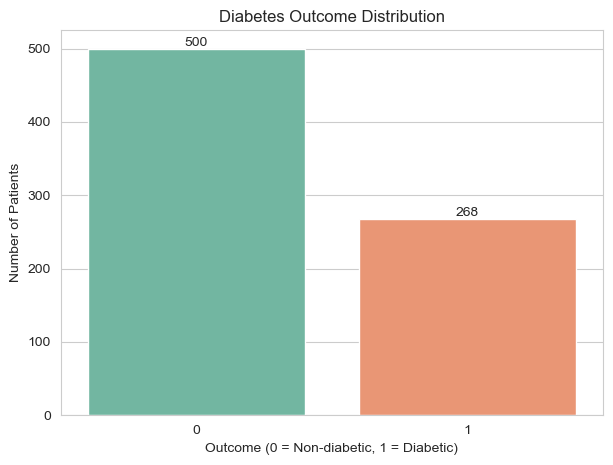

In [8]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Outcome", hue="Outcome", palette="Set2", legend=False)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = Non-diabetic, 1 = Diabetic)")
plt.ylabel("Number of Patients")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

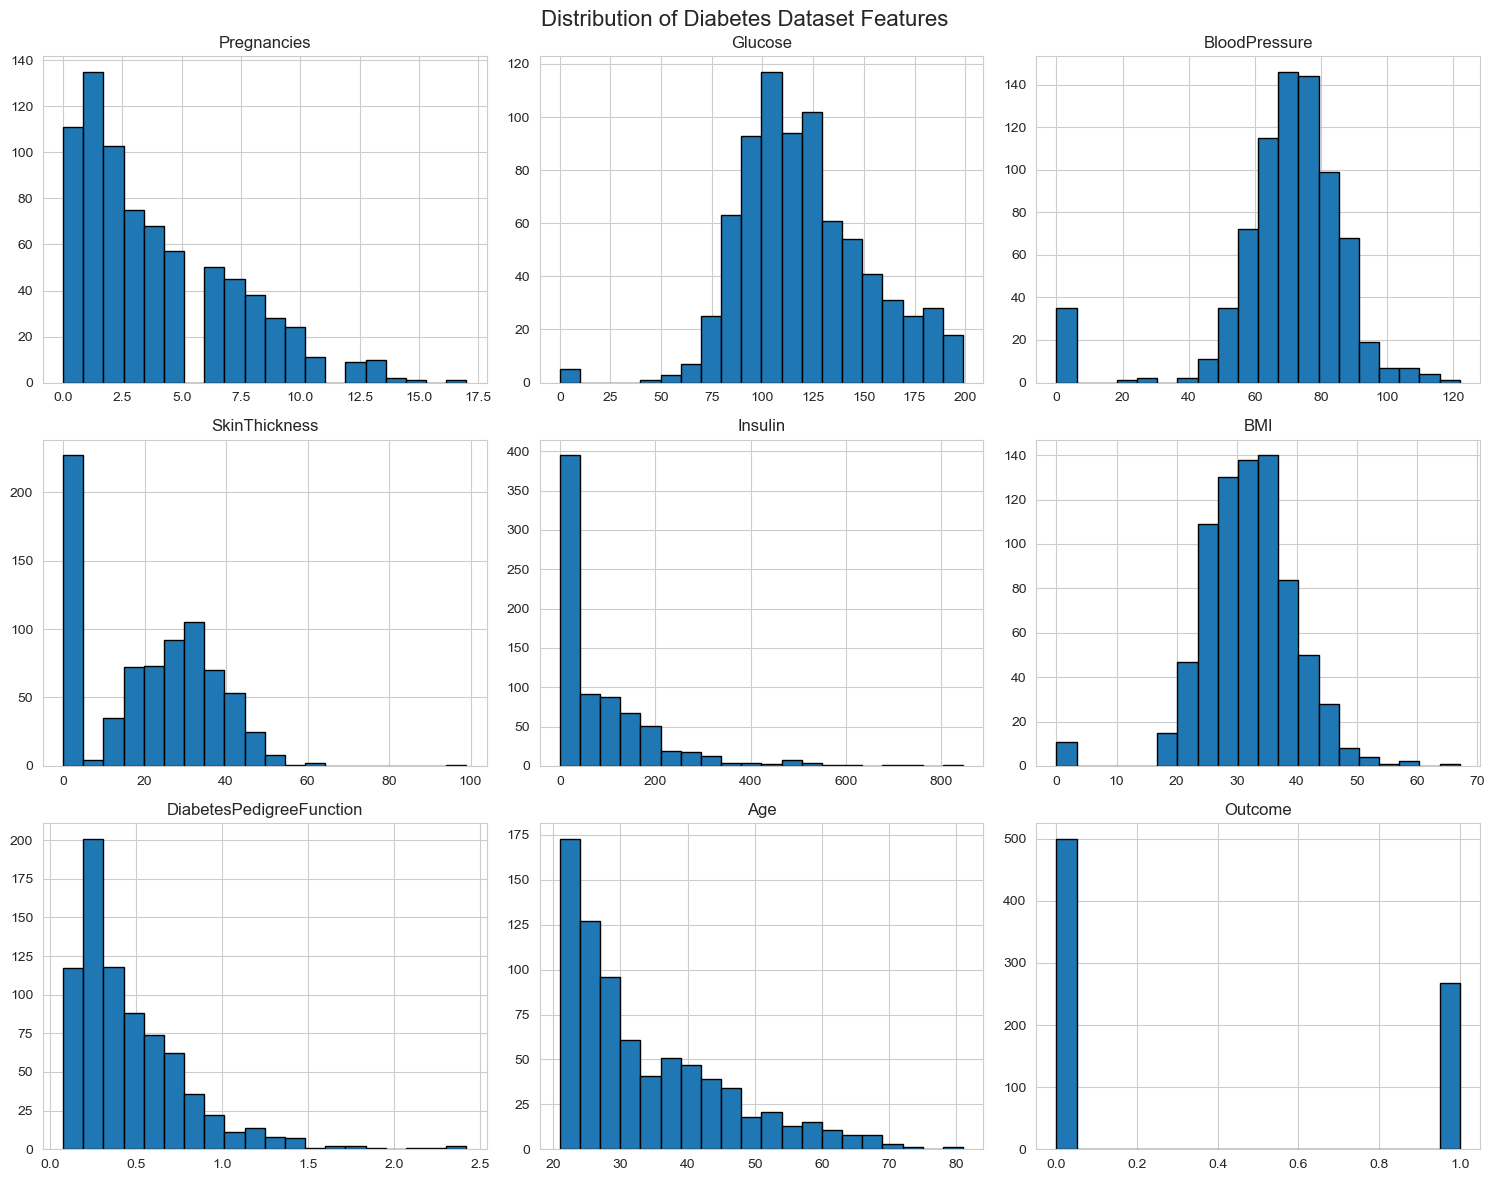

In [9]:
df.hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Diabetes Dataset Features", fontsize=16)

plt.tight_layout()
plt.show()

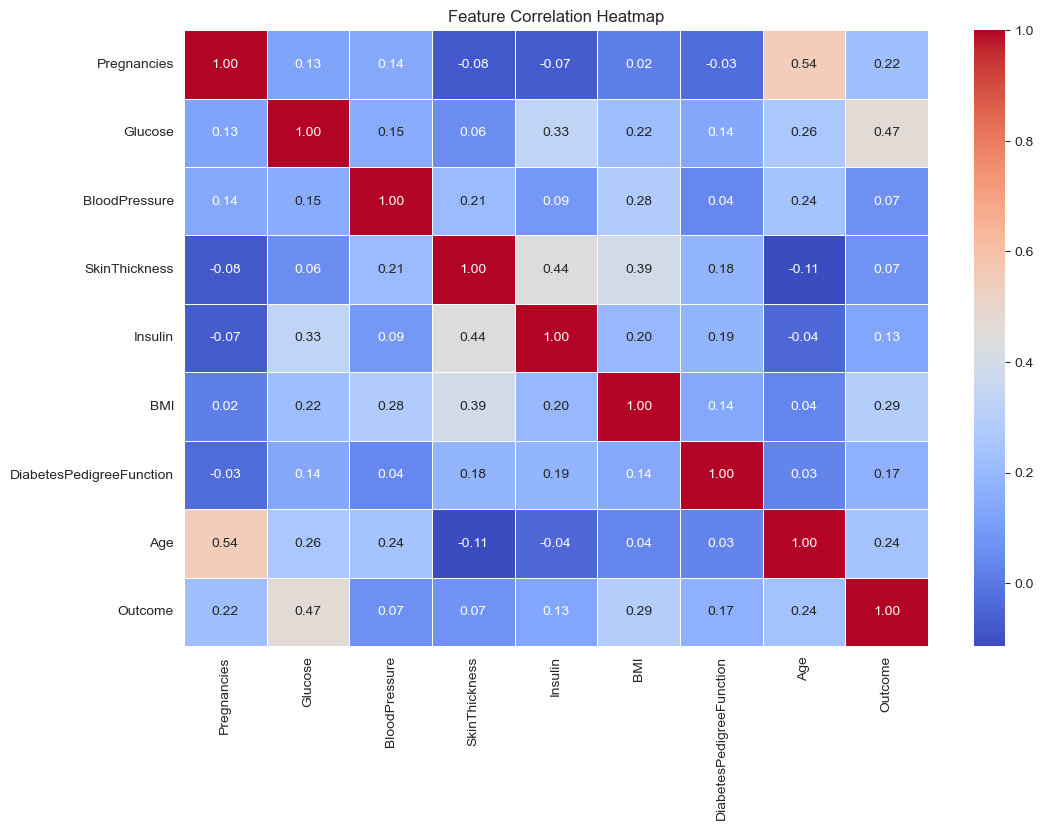

In [10]:
plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [11]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_analysis = pd.DataFrame({
    "Feature": zero_columns,
    "Zero_Count": [(df[col] == 0).sum() for col in zero_columns]
})

zero_analysis["Percentage"] = (
    zero_analysis["Zero_Count"] / len(df) * 100
).round(2)

display(zero_analysis)

,Feature,Zero_Count,Percentage
0,Glucose,5,0.65
1,BloodPressure,35,4.56
2,SkinThickness,227,29.56
3,Insulin,374,48.70
4,BMI,11,1.43


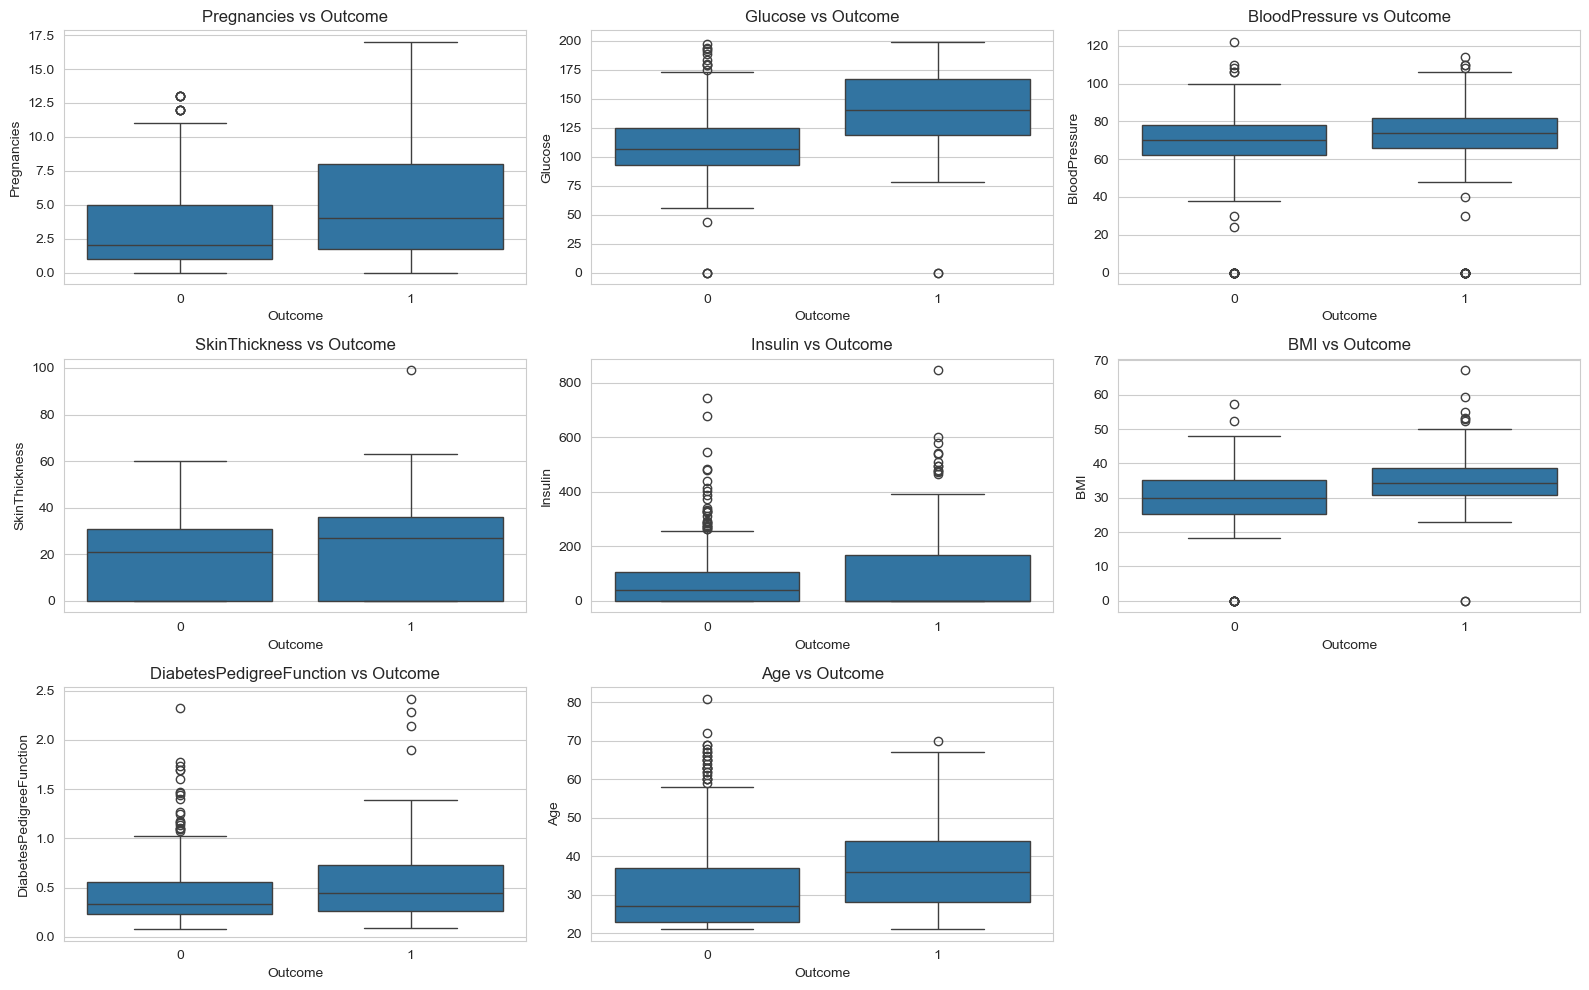

In [12]:
plt.figure(figsize=(16, 10))

for i, col in enumerate(df.columns[:-1], 1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=df, x="Outcome", y=col)
    plt.title(f"{col} vs Outcome")

plt.tight_layout()
plt.show()

In [13]:
# Columns where zero represents an invalid measurement
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Create a copy of original dataset
df_clean = df.copy()

# Replace zero values with NaN
df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

print("Invalid zero values replaced successfully!")

Invalid zero values replaced successfully!


In [14]:
missing_analysis = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

display(missing_analysis)

,Missing_Count,Missing_Percentage
Pregnancies,0,0.00
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,0,0.00


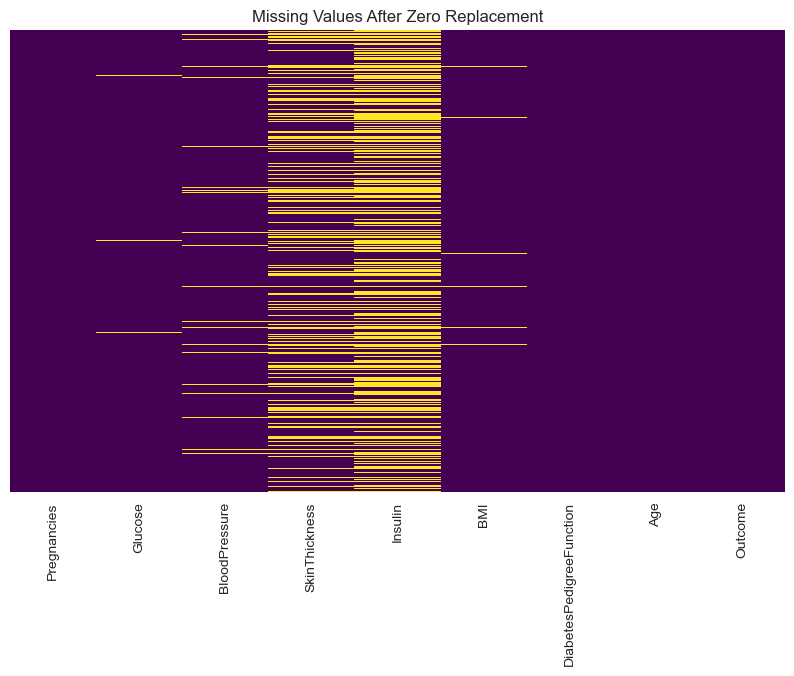

In [15]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df_clean.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values After Zero Replacement")
plt.show()

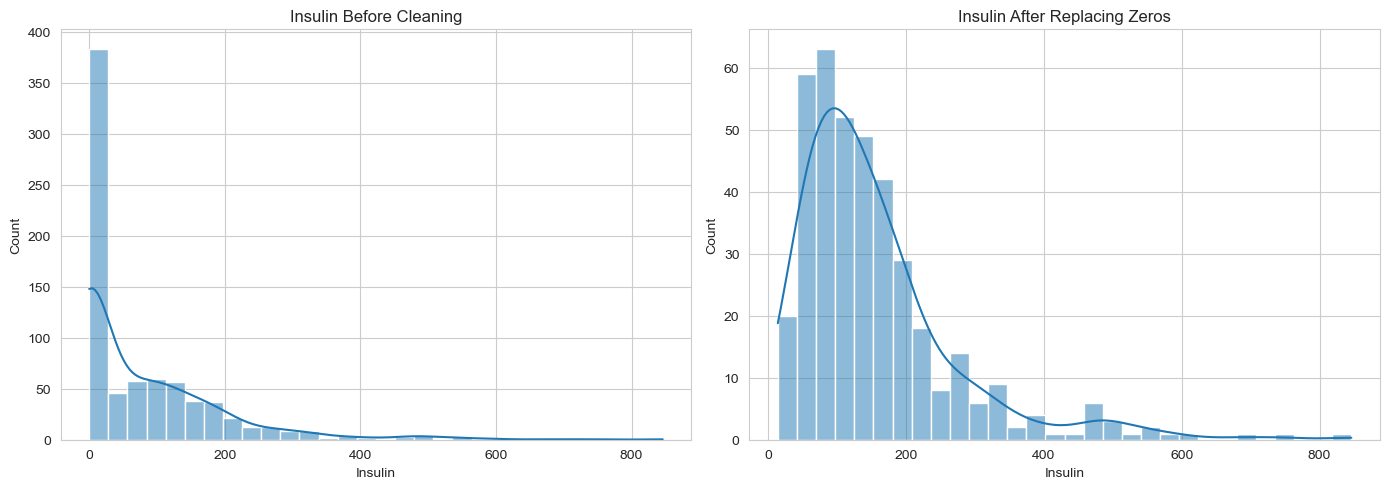

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Insulin"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Insulin Before Cleaning")

sns.histplot(df_clean["Insulin"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Insulin After Replacing Zeros")

plt.tight_layout()
plt.show()

In [17]:
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training data: (614, 8)
Testing data: (154, 8)

Training distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Testing distribution:
Outcome
0    100
1     54
Name: count, dtype: int64


In [19]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Missing values imputed successfully!")

Missing values imputed successfully!


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Feature scaling completed!")

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Feature scaling completed!
Training shape: (614, 8)
Testing shape: (154, 8)


In [21]:
print("Training NaN values:", np.isnan(X_train_scaled).sum())
print("Testing NaN values:", np.isnan(X_test_scaled).sum())

print("\nTraining feature means:")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nTraining feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0), 3))

Training NaN values: 0
Testing NaN values: 0

Training feature means:
[-0. -0.  0. -0. -0.  0. -0. -0.]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [23]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Models initialized successfully!")

Models initialized successfully!


In [24]:
trained_models = {}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Support Vector Machine trained successfully!
Random Forest trained successfully!


In [25]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.7727,0.7021,0.6111,0.6535,0.8181
1,Support Vector Machine,0.7403,0.6522,0.5556,0.6000,0.7964
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130


In [26]:
for name, model in trained_models.items():

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    y_pred = model.predict(X_test_scaled)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Non-Diabetic", "Diabetic"]
    ))


Logistic Regression
              precision    recall  f1-score   support

Non-Diabetic       0.75      0.82      0.78       100
    Diabetic       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


Support Vector Machine
              precision    recall  f1-score   support

Non-Diabetic       0.78      0.84      0.81       100
    Diabetic       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154


Random Forest
              precision    recall  f1-score   support

Non-Diabetic       0.80      0.86      0.83       100
    Diabetic       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg  

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [28]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# SVM pipeline
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True, random_state=42))
])

# Random Forest pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=42))
])

print("Pipelines created successfully!")

Pipelines created successfully!


In [29]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
        "model__solver": ["liblinear"]
    },

    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2],
        "model__class_weight": [None, "balanced"]
    }
}

pipelines = {
    "Logistic Regression": lr_pipeline,
    "SVM": svm_pipeline,
    "Random Forest": rf_pipeline
}

In [30]:
best_models = {}
tuning_results = []

for name, pipeline in pipelines.items():

    print(f"\nTuning {name}...")

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1 Score": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

    print("Best CV F1:", round(grid.best_score_, 4))
    print("Best Parameters:", grid.best_params_)


Tuning Logistic Regression...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV F1: 0.6792
Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}

Tuning SVM...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV F1: 0.6902
Best Parameters: {'model__C': 1, 'model__class_weight': 'balanced', 'model__kernel': 'rbf'}

Tuning Random Forest...
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best CV F1: 0.7078
Best Parameters: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}


In [31]:
tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        by="Best CV F1 Score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Best CV F1 Score,Best Parameters
0,Random Forest,0.707846,"{'model__class_weight': 'balanced', 'model__ma..."
1,SVM,0.690163,"{'model__C': 1, 'model__class_weight': 'balanc..."
2,Logistic Regression,0.679190,"{'model__C': 0.1, 'model__class_weight': 'bala..."


In [32]:
tuned_results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

display(
    tuned_results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.7338,0.5970,0.7407,0.6612,0.8204
1,SVM,0.7273,0.5909,0.7222,0.6500,0.8139
0,Logistic Regression,0.7208,0.5846,0.7037,0.6387,0.8106


In [33]:
best_rf = best_models["Random Forest"]

y_pred_rf = best_rf.predict(X_test)

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Non-Diabetic", "Diabetic"]
))


              precision    recall  f1-score   support

Non-Diabetic       0.84      0.73      0.78       100
    Diabetic       0.60      0.74      0.66        54

    accuracy                           0.73       154
   macro avg       0.72      0.74      0.72       154
weighted avg       0.75      0.73      0.74       154



Confusion Matrix:
[[73 27]
 [14 40]]


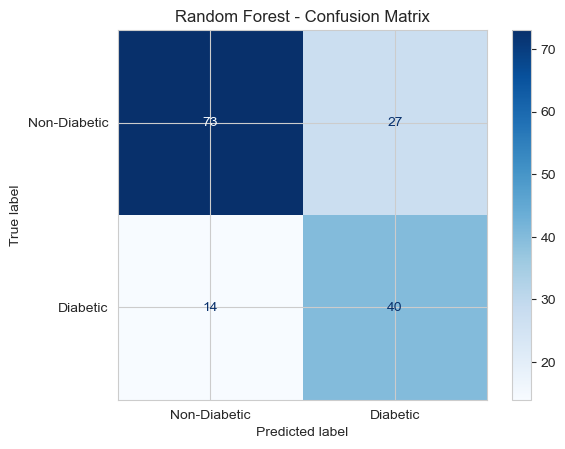

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_rf = best_models["Random Forest"]
y_pred_rf = best_rf.predict(X_test)

cm = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

,Feature,Importance
1,Glucose,0.336968
5,BMI,0.181828
7,Age,0.126210
4,Insulin,0.114879
6,DiabetesPedigreeFunction,0.076353
0,Pregnancies,0.059457
3,SkinThickness,0.053181
2,BloodPressure,0.051126


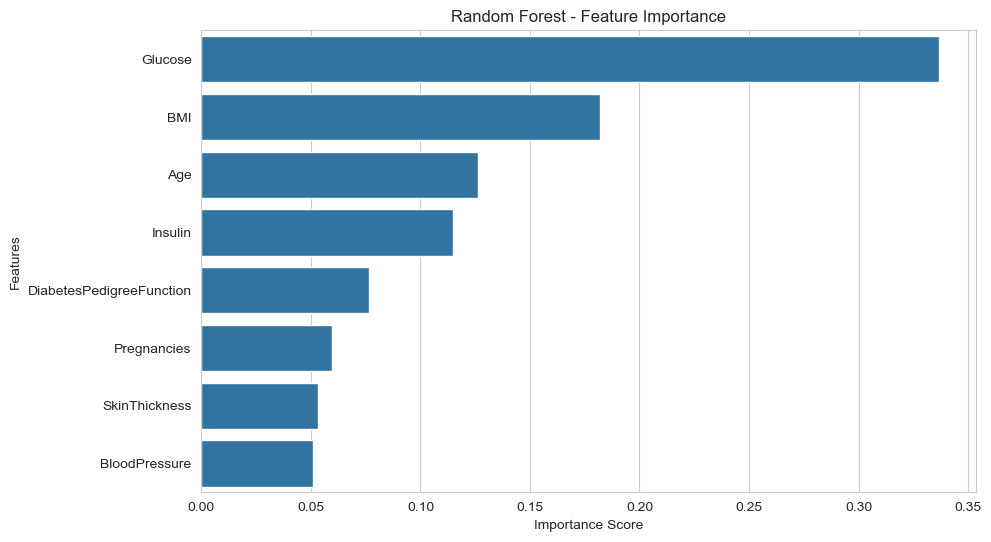

In [35]:
rf_model = best_rf.named_steps["model"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [36]:
import joblib
from pathlib import Path

# Create models folder if it doesn't exist
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the complete pipeline
model_path = model_dir / "diabetes_prediction_model.pkl"

joblib.dump(best_rf, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())

Model saved successfully!
Saved location: C:\Users\picka\OneDrive\Desktop\Diabetes_Prediction\Diabetes_Prediction\models\diabetes_prediction_model.pkl


In [37]:
# Load the saved pipeline
loaded_model = joblib.load(model_path)

# Make predictions using the loaded model
sample_predictions = loaded_model.predict(X_test.iloc[:5])

print("Actual values:   ", y_test.iloc[:5].values)
print("Predictions:     ", sample_predictions)

Actual values:    [0 0 0 1 0]
Predictions:      [1 0 0 0 0]
